# Code examples for plotting the proton flux

In [1]:
import astropy.units as u
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from mario.sources import Accelerator
G8 = Accelerator(name='SNR G8.7-0.1', 
                 glon=8.744205*u.deg, glat=-0.096288*u.deg, radius=0.375*u.deg,
                 age=15*u.kyr, distance=4.5*u.kpc, gas_mass=7.9e5*u.solMass)

### Define the total column density map and class

In [3]:
from mario.gas_utilities import GasParameters, calc_average_number_density, calc_n0
gas = '/home/kirsty/Documents/PhD/Fits_Files/Models/total_col_dens_30_40.fits'
gp = GasParameters(acc=G8, gas_map_path=gas)

### Determine the SNR evolution number density, n0

In [4]:
from mario.gas_utilities import calc_n0
E_SN=1e51*u.erg
n0 = calc_n0(R_acc=G8.radius_pc, t_acc=G8.age, E_SN=E_SN)

### Create PDF function based on those parameters

In [5]:
from mario.models.hadronic_models import HadronicImpulsiveTime
ps = HadronicImpulsiveTime(n=100*u.cm**(-3),
                           n0=n0,
                           dif_chi=0.1,
                           dif_delta=0.3,
                           deltap=0.2,
                           Epmin=1*u.GeV,
                           Epmax=1*u.PeV,
                           Mej=1*u.solMass,
                           E_SN=E_SN)

### Use the maker class to plot the proton spectra

In [6]:
from mario.models.hadronic_models import HadronicImpulsiveMaker
maker = HadronicImpulsiveMaker(ps=ps, acc=G8, gp=gp, alpha=2.2, eta=0.1)

/home/kirsty/anaconda3/envs/gammapy-0.18.2/lib/python3.7/site-packages/astropy/units/quantity.py:477: RuntimeWarning: invalid value encountered in sqrt
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)


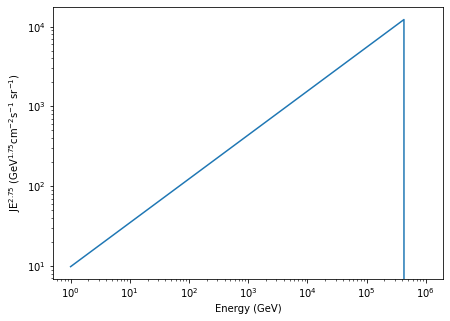

In [7]:
Ep = np.logspace(0, 6, 50)*u.GeV
R = 10*u.pc
maker.plot_proton_spectra(energies=Ep, radius=R)

/home/kirsty/anaconda3/envs/gammapy-0.18.2/lib/python3.7/site-packages/astropy/units/quantity.py:477: RuntimeWarning: invalid value encountered in sqrt
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)


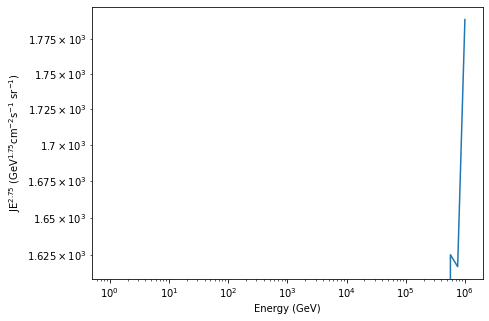

In [8]:
Ep = np.logspace(0, 6, 50)*u.GeV
R = 30*u.pc
maker.plot_proton_spectra(energies=Ep, radius=R)

### Use maker class to plot the proton flux at a specific energy

In [9]:
ps = HadronicImpulsiveTime(n=100*u.cm**(-3),
                           n0=n0,
                           dif_chi=0.1,
                           dif_delta=0.3,
                           deltap=2.5,
                           Epmin=1*u.GeV,
                           Epmax=1*u.PeV,
                           Mej=1*u.solMass,
                           E_SN=E_SN)

In [10]:
maker = HadronicImpulsiveMaker(ps=ps, acc=G8, gp=gp, alpha=2.2, eta=0.1)
# Jps = maker.calc_proton_flux(energy=10*u.TeV)

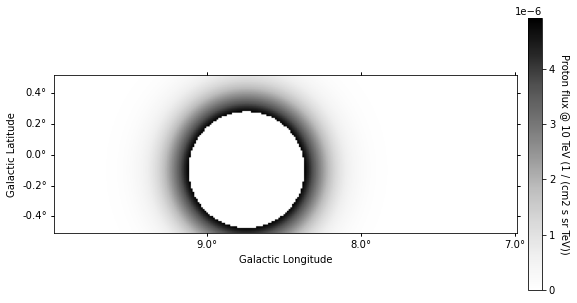

In [11]:
maker.plot_proton_flux(energy=10*u.TeV, cmap='Greys')

## Save PDF

In [12]:
from mario.gas_utilities import GasParameters, calc_average_number_density
gas = '/home/kirsty/Documents/PhD/Fits_Files/Models/total_col_dens_30_40.fits'
gp = GasParameters(acc=G8, gas_map_path=gas)

In [13]:
from mario.sources import GammaSource
hess = GammaSource(name='HESS J1804', spectral_index=2.69, 
                   glon=8.4*u.deg, glat=-0.03*u.deg, radius=0.367*u.deg, 
                   flux_GeV=1.56e-9 / (u.s * u.cm**2),
                   flux_E_GeV=0.01 * u.TeV,
                   flux_TeV=5.32e-11/(u.s * u.cm**2),
                   flux_E_TeV=0.2 * u.TeV)

In [14]:
n = calc_average_number_density(gas, hess, G8)
ps = HadronicImpulsiveTime(n=n,
                           n0=n0,
                           dif_chi=0.01,
                           dif_delta=0.6,
                           deltap=2.5,
                           Epmin=1*u.GeV,
                           Epmax=1*u.PeV,
                           Mej=20*u.solMass,
                           E_SN=E_SN)

Ep = np.logspace(0, np.log10(ps.Epmax.to(u.GeV).value), 1000)*u.GeV
ps.calc_pdf(E=Ep, R=gp.dist_cell(), t=G8.age)

/home/kirsty/anaconda3/envs/gammapy-0.18.2/lib/python3.7/site-packages/astropy/units/quantity.py:477: RuntimeWarning: invalid value encountered in sqrt
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)


In [15]:
extra_comments = {'HGAM_SRC':hess.name,
                  'HACC':G8.name,
                  'HGASPATH':gas}
ps.save(author='Kirsty Feijen', extra_comments=extra_comments)